In [ ]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import time
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from src.data_jerem import build
from src.utils_jerem import evaluate, log_result

d = build("base", horizon=1)
print({k: v.shape for k, v in d.items()})

pers = evaluate(d["y_val"], d["X_val"][:, 9])
print("persistance t+1 :", pers)          # attendu : RMSE ≈ 0.0381
log_result("persistance", "base-h1", "col9", "val", pers)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
{'X_train': (36288, 48), 'y_train': (36288,), 'X_val': (9108, 48), 'y_val': (9108,), 'X_test': (30240, 48), 'y_test': (30240,), 'X_trainval': (45396, 48), 'y_trainval': (45396,)}
persistance t+1 : {'RMSE': 0.03809453642424843, 'MAE': 0.025418882281786653}


In [4]:
t0 = time.time()
xgb = XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=6,
                   early_stopping_rounds=50, random_state=0, n_jobs=-1)
xgb.fit(d["X_train"], d["y_train"], eval_set=[(d["X_val"], d["y_val"])], verbose=False)
n_best = xgb.best_iteration + 1
m = evaluate(d["y_val"], xgb.predict(d["X_val"], iteration_range=(0, n_best)))
dt = time.time() - t0
print("xgb :", m, "| arbres retenus :", n_best, f"| {dt:.1f}s")
log_result("xgb", "base-h1", f"lr=0.05,depth=6,n={n_best},fit_s={dt:.1f}", "val", m)

t0 = time.time()
rf = RandomForestRegressor(n_estimators=200, max_depth=10, n_jobs=-1, random_state=0)
rf.fit(d["X_train"], d["y_train"])
m = evaluate(d["y_val"], rf.predict(d["X_val"]))
dt = time.time() - t0
print("rf  :", m, f"| {dt:.1f}s")
log_result("rf", "base-h1", f"n=200,depth=10,fit_s={dt:.1f}", "val", m)

xgb : {'RMSE': 0.031131969593118123, 'MAE': 0.019985769669414996} | arbres retenus : 387 | 1.6s
rf  : {'RMSE': 0.03331800917167995, 'MAE': 0.021728176743945348} | 4.1s


In [5]:
rng = np.random.default_rng(0)

def sample_xgb():
    return dict(learning_rate=float(10 ** rng.uniform(-2, -0.7)),        # 0.01 à 0.2
                max_depth=int(rng.integers(3, 10)),
                min_child_weight=float(10 ** rng.uniform(0, 1.5)),       # 1 à 30
                subsample=float(rng.uniform(0.6, 1.0)),
                colsample_bytree=float(rng.uniform(0.5, 1.0)),
                reg_lambda=float(10 ** rng.uniform(-1, 1.5)),            # 0.1 à 30
                reg_alpha=float(10 ** rng.uniform(-3, 0)))

rows = []
for k in range(60):
    p = sample_xgb()
    t0 = time.time()
    mdl = XGBRegressor(n_estimators=2000, early_stopping_rounds=50,
                       random_state=0, n_jobs=-1, **p)
    mdl.fit(d["X_train"], d["y_train"], eval_set=[(d["X_val"], d["y_val"])], verbose=False)
    p["n_estimators"] = mdl.best_iteration + 1
    m = evaluate(d["y_val"], mdl.predict(d["X_val"], iteration_range=(0, p["n_estimators"])))
    dt = time.time() - t0
    log_result("xgb", "base-h1", ",".join(f"{a}={b:.4g}" for a, b in p.items()) + f",fit_s={dt:.1f}", "val", m)
    rows.append({**p, **m, "fit_s": dt})

xgb_res = pd.DataFrame(rows).sort_values("RMSE")
print(xgb_res.head(5).round(4).to_string(index=False))

 learning_rate  max_depth  min_child_weight  subsample  colsample_bytree  reg_lambda  reg_alpha  n_estimators   RMSE    MAE  fit_s
        0.0326          8           20.4307     0.7889            0.9563      8.2185     0.5571           647 0.0306 0.0196 2.6444
        0.0867          9            6.1381     0.7241            0.7429     16.7386     0.6341           254 0.0307 0.0196 1.3400
        0.0267          7           10.2849     0.7451            0.6649     22.8662     0.0040           759 0.0307 0.0195 2.5956
        0.0461          7           31.0725     0.7264            0.5914     15.8579     0.2735           619 0.0307 0.0196 2.2320
        0.0822          5           29.6990     0.9375            0.7121     28.1334     0.8355           625 0.0307 0.0198 1.6669


In [6]:
rows = []
for n in (100, 300):
    for md in (None, 10, 20):
        for msl in (1, 5):
            for mf in (0.5, 1.0):
                t0 = time.time()
                rf = RandomForestRegressor(n_estimators=n, max_depth=md, min_samples_leaf=msl,
                                           max_features=mf, n_jobs=-1, random_state=0)
                rf.fit(d["X_train"], d["y_train"])
                m = evaluate(d["y_val"], rf.predict(d["X_val"]))
                dt = time.time() - t0
                log_result("rf", "base-h1", f"n={n},depth={md},leaf={msl},mf={mf},fit_s={dt:.1f}", "val", m)
                rows.append(dict(n=n, depth=md, leaf=msl, mf=mf, **m, fit_s=dt))

rf_res = pd.DataFrame(rows).sort_values("RMSE")
print(rf_res.head(5).round(4).to_string(index=False))

  n  depth  leaf  mf   RMSE    MAE  fit_s
300    NaN     1 0.5 0.0313 0.0199 5.1025
300   20.0     1 0.5 0.0313 0.0200 4.3963
300    NaN     5 0.5 0.0314 0.0200 3.6755
100    NaN     1 0.5 0.0314 0.0200 1.8888
300   20.0     5 0.5 0.0314 0.0201 3.5849


In [7]:
# Meilleurs réglages trouvés (on prend la première ligne de chaque tableau trié)
xp = {k: float(xgb_res.iloc[0][k]) for k in
      ["learning_rate", "min_child_weight", "subsample", "colsample_bytree", "reg_lambda", "reg_alpha"]}
xp["max_depth"] = int(xgb_res.iloc[0]["max_depth"])

def run_xgb(d, delta):
    b_tr = d["X_train"][:, 9] if delta else 0
    b_va = d["X_val"][:, 9] if delta else 0
    mdl = XGBRegressor(n_estimators=2000, early_stopping_rounds=50, random_state=0, n_jobs=-1, **xp)
    mdl.fit(d["X_train"], d["y_train"] - b_tr, eval_set=[(d["X_val"], d["y_val"] - b_va)], verbose=False)
    n = mdl.best_iteration + 1
    pred = b_va + mdl.predict(d["X_val"], iteration_range=(0, n))
    return evaluate(d["y_val"], pred), n

def run_rf(d, delta):
    b_tr = d["X_train"][:, 9] if delta else 0
    b_va = d["X_val"][:, 9] if delta else 0
    mdl = RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_leaf=1,
                                max_features=0.5, n_jobs=-1, random_state=0)
    mdl.fit(d["X_train"], d["y_train"] - b_tr)
    return evaluate(d["y_val"], b_va + mdl.predict(d["X_val"])), 300

rows = []
for variant in ["base", "spatial"]:
    dv = build(variant, horizon=1)
    for delta in [False, True]:
        for name, fn in [("xgb", run_xgb), ("rf", run_rf)]:
            t0 = time.time()
            m, n = fn(dv, delta)
            dt = time.time() - t0
            cible = "variation" if delta else "niveau"
            log_result(name, f"{variant}-h1", f"cible={cible},n={n},fit_s={dt:.1f}", "val", m)
            rows.append(dict(modele=name, variante=variant, cible=cible, **m))
print(pd.DataFrame(rows).round(4).to_string(index=False))

modele variante     cible   RMSE    MAE
   xgb     base    niveau 0.0306 0.0196
    rf     base    niveau 0.0313 0.0199
   xgb     base variation 0.0306 0.0196
    rf     base variation 0.0304 0.0193
   xgb  spatial    niveau 0.0302 0.0193
    rf  spatial    niveau 0.0310 0.0197
   xgb  spatial variation 0.0303 0.0193
    rf  spatial variation 0.0304 0.0193


In [8]:
from sklearn.model_selection import TimeSeriesSplit

n_fix = int(xgb_res.head(5)["n_estimators"].median())      # nombre d'arbres fixé, sans arrêt anticipé

makers = {
    "xgb": lambda: XGBRegressor(n_estimators=n_fix, random_state=0, n_jobs=-1, **xp),
    "rf":  lambda: RandomForestRegressor(n_estimators=300, max_features=0.5, n_jobs=-1, random_state=0),
}

def cv_scores(name, variant, delta, n_splits=4):
    d = build(variant, horizon=1)
    X, y = d["X_trainval"], d["y_trainval"]               # lignes rangées instant par instant
    base = X[:, 9] if delta else np.zeros(len(X))
    out = []
    for tr, va in TimeSeriesSplit(n_splits=n_splits, test_size=36 * 96).split(X):
        mdl = makers[name]()
        mdl.fit(X[tr], y[tr] - base[tr])
        pred = base[va] + mdl.predict(X[va])
        out.append((evaluate(y[va], pred)["RMSE"], evaluate(y[va], X[va, 9])["RMSE"]))
    return np.array(out)                                   # colonnes : modèle, persistance

rows = []
for name, variant, delta in [("xgb", "base", False), ("xgb", "spatial", False),
                             ("rf", "base", True), ("rf", "spatial", True)]:
    s = cv_scores(name, variant, delta)
    rows.append(dict(modele=name, variante=variant, cible="variation" if delta else "niveau",
                     RMSE_moy=s[:, 0].mean(), ecart_type=s[:, 0].std(),
                     gain_vs_persistance=1 - (s[:, 0] / s[:, 1]).mean(),
                     plis_battant_persistance=int((s[:, 0] < s[:, 1]).sum())))
print(pd.DataFrame(rows).round(4).to_string(index=False))

modele variante     cible  RMSE_moy  ecart_type  gain_vs_persistance  plis_battant_persistance
   xgb     base    niveau    0.0332      0.0047               0.1770                         4
   xgb  spatial    niveau    0.0330      0.0049               0.1818                         4
    rf     base variation    0.0334      0.0052               0.1724                         4
    rf  spatial variation    0.0334      0.0054               0.1749                         4


In [9]:
res = {(n, v): cv_scores(n, v, dl) for n, v, dl in
       [("xgb", "base", False), ("xgb", "spatial", False), ("rf", "base", True), ("rf", "spatial", True)]}
for n in ("xgb", "rf"):
    diff = res[(n, "base")][:, 0] - res[(n, "spatial")][:, 0]
    print(n, "gain spatial par pli :", diff.round(4), "| plis gagnés :", int((diff > 0).sum()), "/ 4")

xgb gain spatial par pli : [-0.     -0.0001  0.0004  0.0004] | plis gagnés : 2 / 4
rf gain spatial par pli : [-0.0001 -0.0002  0.0003  0.0003] | plis gagnés : 2 / 4


In [10]:
def add_features(X, trend=False, network=False):
    """X : lignes rangées instant par instant (36 capteurs par instant) ; colonnes 0 à 9 = lags."""
    T = len(X) // 36
    X3 = X.reshape(T, 36, -1)
    extra = []
    if trend:
        extra += [X3[:, :, 9:10] - X3[:, :, 8:9],          # v_t - v_(t-1)
                  X3[:, :, 9:10] - X3[:, :, 7:8],          # v_t - v_(t-2)
                  X3[:, :, 0:10].mean(2, keepdims=True)]   # moyenne des 10 lags
    if network:
        last = X3[:, :, 9]                                 # dernier débit de chacun des 36 capteurs
        extra.append(np.repeat(last[:, None, :], 36, axis=1))
    return np.concatenate([X3] + extra, axis=2).reshape(T * 36, -1)

d = build("base", horizon=1, sensor_id="int")     # l'identifiant de capteur donne un sens aux colonnes « réseau »
tests = {"base": dict(), "tendance": dict(trend=True),
         "réseau": dict(network=True), "tendance+réseau": dict(trend=True, network=True)}
for name, kw in tests.items():
    Xtr, Xva = add_features(d["X_train"], **kw), add_features(d["X_val"], **kw)
    mdl = XGBRegressor(n_estimators=2000, early_stopping_rounds=50, random_state=0, n_jobs=-1, **xp)
    mdl.fit(Xtr, d["y_train"], eval_set=[(Xva, d["y_val"])], verbose=False)
    n = mdl.best_iteration + 1
    m = evaluate(d["y_val"], mdl.predict(Xva, iteration_range=(0, n)))
    print(f"{name:16s}", {k: round(v, 4) for k, v in m.items()}, "arbres :", n)

base             {'RMSE': 0.0304, 'MAE': 0.0194} arbres : 824
tendance         {'RMSE': 0.0303, 'MAE': 0.0194} arbres : 577
réseau           {'RMSE': 0.03, 'MAE': 0.0191} arbres : 898
tendance+réseau  {'RMSE': 0.0301, 'MAE': 0.0191} arbres : 854


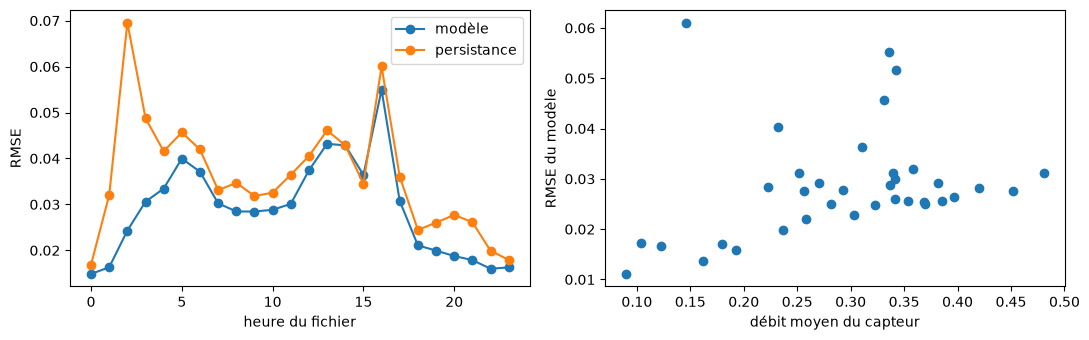

{'10 lags': 0.993, 'jour': 0.0, 'heure': 0.004, 'attributs fixes': 0.002}
{'lag 9': 0.002, 'lag 8': 0.001, 'lag 7': 0.001, 'lag 6': 0.001, 'lag 5': 0.001, 'lag 4': 0.001, 'lag 3': 0.001, 'lag 2': 0.046, 'lag 1': 0.011, 'lag 0': 0.929}


In [11]:
import matplotlib.pyplot as plt

d = build("base", horizon=1)
mdl = XGBRegressor(n_estimators=n_fix, random_state=0, n_jobs=-1, **xp).fit(d["X_train"], d["y_train"])
y, pred, pers = d["y_val"], mdl.predict(d["X_val"]), d["X_val"][:, 9]
hour = d["X_val"][:, 15:39].argmax(1)
sensor = np.tile(np.arange(36), len(y) // 36)           # lignes rangées instant par instant

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

by_hour = pd.DataFrame({h: dict(modèle=rmse(y[hour == h], pred[hour == h]),
                                persistance=rmse(y[hour == h], pers[hour == h]))
                        for h in range(24) if (hour == h).any()}).T
by_sensor = pd.DataFrame({s: dict(modèle=rmse(y[sensor == s], pred[sensor == s]),
                                  persistance=rmse(y[sensor == s], pers[sensor == s]),
                                  niveau_moyen=float(y[sensor == s].mean()))
                          for s in range(36)}).T

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
by_hour.plot(ax=ax[0], marker="o"); ax[0].set_xlabel("heure du fichier"); ax[0].set_ylabel("RMSE")
ax[1].scatter(by_sensor["niveau_moyen"], by_sensor["modèle"])
ax[1].set_xlabel("débit moyen du capteur"); ax[1].set_ylabel("RMSE du modèle")
plt.tight_layout(); plt.show()

# Importance par groupes de colonnes (gain)
groups = {"10 lags": range(0, 10), "jour": range(10, 15), "heure": range(15, 39), "attributs fixes": range(39, 48)}
g = mdl.get_booster().get_score(importance_type="total_gain")
tot = sum(g.values())
print({k: round(sum(g.get(f"f{j}", 0) for j in r) / tot, 3) for k, r in groups.items()})
print({f"lag {9 - j}": round(g.get(f"f{j}", 0) / tot, 3) for j in range(10)})   # lag 0 = dernier débit v_t

In [12]:
rows = []
for horizon in (1, 2):
    for name, variant, delta in [("xgb", "base", False), ("xgb", "spatial", False),
                                 ("rf", "base", True), ("rf", "spatial", True)]:
        d = build(variant, horizon=horizon)
        b_tv = d["X_trainval"][:, 9] if delta else 0
        b_te = d["X_test"][:, 9] if delta else 0
        t0 = time.time()
        mdl = makers[name]().fit(d["X_trainval"], d["y_trainval"] - b_tv)
        dt = time.time() - t0
        m = evaluate(d["y_test"], b_te + mdl.predict(d["X_test"]))
        cible = "variation" if delta else "niveau"
        log_result(name, f"{variant}-h{horizon}", f"FINAL,cible={cible},fit_s={dt:.1f}", "test", m)
        rows.append(dict(h=horizon, modele=name, variante=variant, cible=cible, fit_s=round(dt, 1), **m))
    p = evaluate(d["y_test"], d["X_test"][:, 9])                # persistance, pour mémoire
    rows.append(dict(h=horizon, modele="persistance", variante="-", cible="-", fit_s=0.0, **p))
print(pd.DataFrame(rows).round(4).to_string(index=False))

 h      modele variante     cible  fit_s   RMSE    MAE
 1         xgb     base    niveau    2.5 0.0312 0.0212
 1         xgb  spatial    niveau    2.8 0.0310 0.0210
 1          rf     base variation   10.3 0.0309 0.0208
 1          rf  spatial variation   19.0 0.0311 0.0209
 1 persistance        -         -    0.0 0.0388 0.0266
 2         xgb     base    niveau    2.5 0.0358 0.0241
 2         xgb  spatial    niveau    2.8 0.0357 0.0240
 2          rf     base variation    9.6 0.0353 0.0234
 2          rf  spatial variation   17.4 0.0355 0.0235
 2 persistance        -         -    0.0 0.0545 0.0372
